# Predição de Falhas em Máquinas Industriais com Machine Learning

**Disciplina:** Machine Learning  
**Curso:** Pós-Graduação em IA Generativa e Aplicações com LLMs – PUC Minas  
**Alunos:** Everton Recalde Franco e Silva

**Dataset:** AI4I 2020 Predictive Maintenance Dataset  
**Fonte:** UCI Machine Learning Repository  
https://archive.ics.uci.edu/dataset/601/ai4i%2B2020%2B

## Objetivo

Este projeto tem como objetivo desenvolver um modelo de Machine Learning capaz de prever falhas em máquinas industriais a partir de características operacionais.

Serão comparados dois algoritmos de classificação: Regressão Logística e Random Forest. O melhor modelo será selecionado a partir das métricas de avaliação e posteriormente integrado a uma interface gráfica desenvolvida em Streamlit.

A aplicação permitirá informar características operacionais de uma máquina e obter uma estimativa da ocorrência de falha.


## 1. Importação das bibliotecas

As bibliotecas necessárias são importadas no início do notebook. A semente aleatória é fixada em 42 para favorecer a reprodutibilidade do experimento.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
)

np.random.seed(42)

print("Bibliotecas carregadas com sucesso!")


Bibliotecas carregadas com sucesso!


## 2. Carregamento e inspeção dos dados

No Google Colab, o dataset será enviado a partir do computador. Após o upload, o arquivo será carregado com Pandas.


In [ ]:
#df = pd.read_csv("ai4i2020.csv")

In [7]:
from google.colab import drive
drive.mount('/content/drive')

caminho_arquivo = '/content/drive/MyDrive/Pos_IA/Machine_Learning/Trabalho_final/ai4i2020.csv'
df = pd.read_csv(caminho_arquivo)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [9]:
print(f"Quantidade de registros: {df.shape[0]}")
print(f"Quantidade de colunas: {df.shape[1]}")

print("\nTipos de dados:")
df.info()


Quantidade de registros: 10000
Quantidade de colunas: 14

Tipos de dados:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF

In [10]:
print("Valores ausentes por coluna:")
display(df.isnull().sum())

print("\nQuantidade de registros duplicados:")
print(df.duplicated().sum())


Valores ausentes por coluna:


,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0



Quantidade de registros duplicados:
0


In [11]:
df.describe()


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


### Análise inicial

O dataset contém 10.000 registros e 14 atributos estruturados. A análise inicial demonstrou que não há valores ausentes (nulos) nem registros duplicados em nenhuma das colunas, o que simplifica o pré-processamento. As estatísticas descritivas revelam que as variáveis operacionais possuem faixas bem definidas, como o torque médio de aproximadamente 40 Nm e o desgaste de ferramenta variando de 0 a 253 minutos. Essas características indicam uma base de dados limpa e consistente para a modelagem preditiva.

## 3. Análise Exploratória dos Dados (EDA)

A análise exploratória busca compreender as principais características do dataset e identificar padrões relacionados à ocorrência de falhas. Serão utilizados pelo menos quatro gráficos, conforme solicitado no trabalho.


,count
Machine failure,
0,9661
1,339


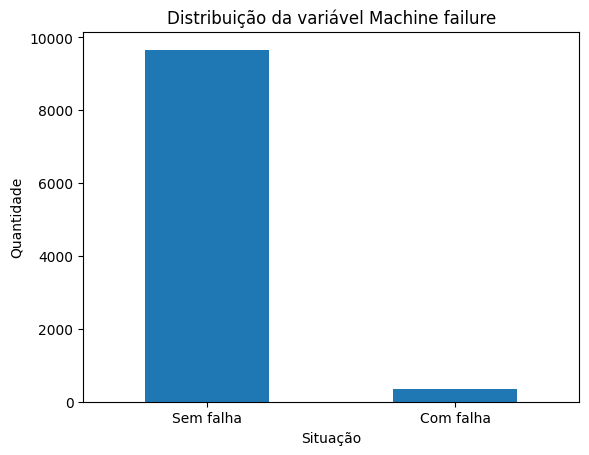


Percentuais:


,proportion
Machine failure,
0,96.61
1,3.39


In [12]:
failure_counts = df["Machine failure"].value_counts().sort_index()

display(failure_counts)

failure_counts.plot(kind="bar")
plt.title("Distribuição da variável Machine failure")
plt.xlabel("Situação")
plt.ylabel("Quantidade")
plt.xticks([0, 1], ["Sem falha", "Com falha"], rotation=0)
plt.show()

print("\nPercentuais:")
display(
    df["Machine failure"]
      .value_counts(normalize=True)
      .sort_index()
      .mul(100)
      .round(2)
)


### Interpretação — Distribuição das falhas

A análise do gráfico revela um desbalanceamento extremo na variável alvo `Machine failure`, onde apenas 3,39% dos registros (339 máquinas) apresentam falha, contra 96,61% sem falhas. Devido a esse cenário, a acurácia isolada se torna uma métrica enganosa, pois um modelo ingênuo que preveja sempre 'Sem falha' alcançaria 96,6% de acerto. Por esse motivo, as métricas de Precision, Recall, F1-Score e a curva ROC-AUC serão as referências principais para avaliar o desempenho real dos classificadores.

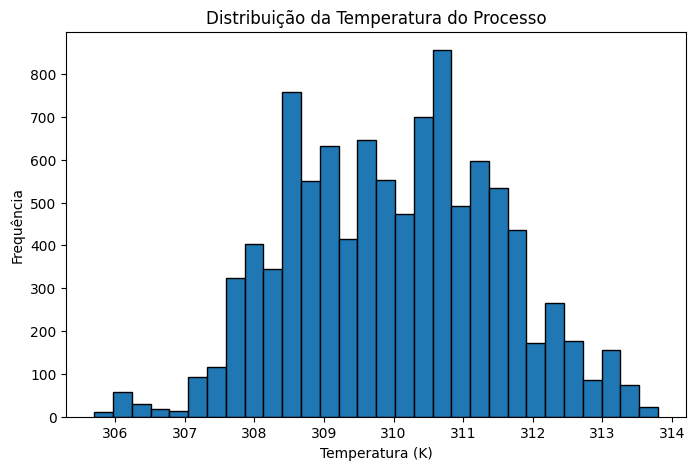

In [13]:
plt.figure(figsize=(8, 5))
plt.hist(df["Process temperature [K]"], bins=30, edgecolor="black")
plt.title("Distribuição da Temperatura do Processo")
plt.xlabel("Temperatura (K)")
plt.ylabel("Frequência")
plt.show()


### Interpretação — Temperatura do processo

A temperatura do processo apresenta uma distribuição aproximadamente normal e bem simétrica, concentrando-se predominantemente na faixa entre 308 K e 312 K, com média próxima de 310 K. Não são observados outliers severos ou valores anômalos que fujam da realidade física industrial esperada. Essa escala uniforme e contínua facilita a normalização dos dados, permitindo que os algoritmos de aprendizado de máquina interpretem a variação térmica sem sofrer distorções causadas por ruídos extremos.

<Figure size 700x500 with 0 Axes>

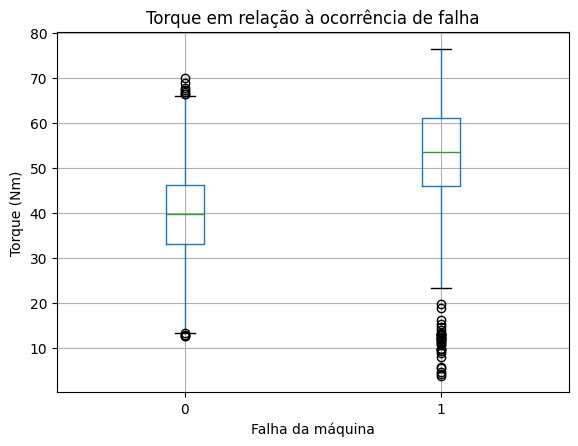

In [14]:
plt.figure(figsize=(7, 5))
df.boxplot(column="Torque [Nm]", by="Machine failure")
plt.title("Torque em relação à ocorrência de falha")
plt.suptitle("")
plt.xlabel("Falha da máquina")
plt.ylabel("Torque (Nm)")
plt.show()


### Interpretação — Torque e falhas

O boxplot indica que o torque possui distribuições visivelmente distintas dependendo do estado da máquina. No grupo que apresentou falha (Machine failure = 1), a dispersão do torque é muito maior, evidenciando uma quantidade significativa de outliers tanto em valores extremamente baixos (próximos de 5 Nm) quanto muito altos (acima de 65 Nm). Em contrapartida, as máquinas que operam normalmente mantêm o torque concentrado em torno da mediana de 40 Nm, sugerindo que anomalias nos limites do torque são fortes indicativos de desgaste ou quebra.

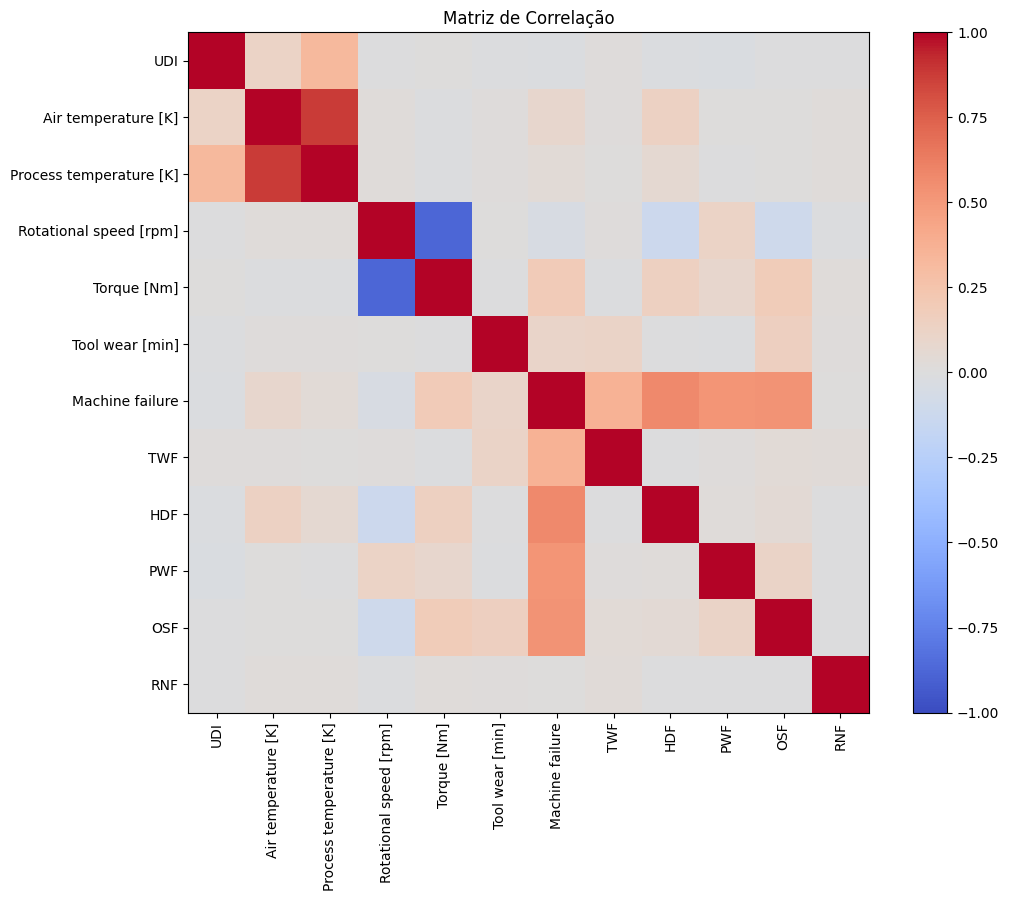

In [15]:
numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticklabels(corr.columns)

fig.colorbar(im)
plt.title("Matriz de Correlação")
plt.tight_layout()
plt.show()


### Interpretação — Matriz de correlação

A matriz de correlação destaca uma correlação linear fortíssima entre a temperatura do ar e a temperatura do processo (próxima a 0.88), o que indica colinearidade esperada no ambiente físico. Nota-se também uma correlação negativa moderada entre a velocidade de rotação e o torque, sugerindo que altas rotações demandam menor torque e vice-versa. Em relação à variável alvo `Machine failure`, as correlações lineares diretas com variáveis individuais são fracas, sinalizando a necessidade de modelos não-lineares, como o Random Forest, para capturar interações complexas.

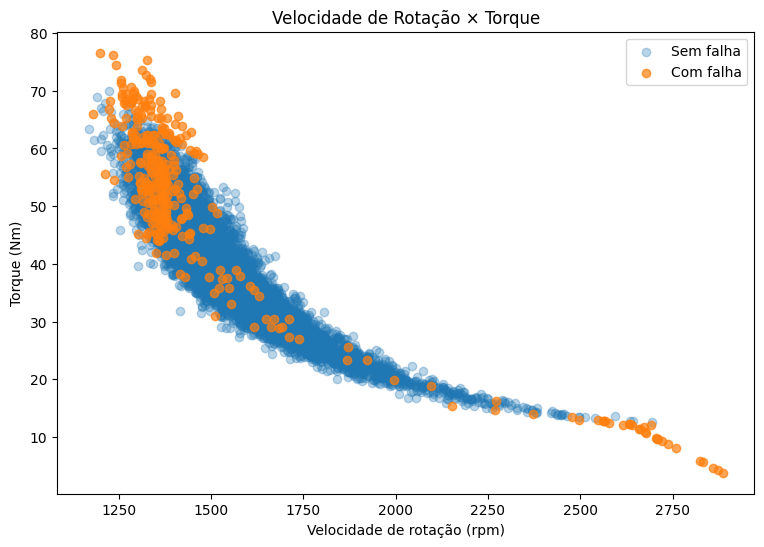

In [16]:
plt.figure(figsize=(9, 6))

normal = df[df["Machine failure"] == 0]
failure = df[df["Machine failure"] == 1]

plt.scatter(
    normal["Rotational speed [rpm]"],
    normal["Torque [Nm]"],
    alpha=0.3,
    label="Sem falha"
)

plt.scatter(
    failure["Rotational speed [rpm]"],
    failure["Torque [Nm]"],
    alpha=0.7,
    label="Com falha"
)

plt.xlabel("Velocidade de rotação (rpm)")
plt.ylabel("Torque (Nm)")
plt.title("Velocidade de Rotação × Torque")
plt.legend()
plt.show()


### Interpretação — Velocidade de rotação × Torque

O gráfico de dispersão ilustra de forma clara a forte relação não-linear entre velocidade e torque, que formam uma curva característica de restrição de potência física. As ocorrências de falha (pontos laranjas) concentram-se predominantemente nos extremos dessa curva: em regiões de baixíssima rotação combinada com torques altíssimos, ou em altas rotações com torques muito baixos. Essa clara separação espacial indica que o cruzamento dessas duas variáveis operacionais é altamente informativo para que o classificador mapeie os limites de operação segura da máquina.

## 4. Pré-processamento

As colunas `UDI` e `Product ID` não serão utilizadas como preditores, pois representam identificadores e não características operacionais úteis para generalização.

A variável categórica `Type` será transformada com One-Hot Encoding. As variáveis numéricas serão padronizadas com StandardScaler.

As transformações serão executadas dentro de um Pipeline para reduzir o risco de vazamento de dados entre treino e teste.


In [17]:
features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

target = "Machine failure"

X = df[features].copy()
y = df[target].copy()

display(X.head())

print("Distribuição do alvo:")
display(y.value_counts())


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


Distribuição do alvo:


,count
Machine failure,
0,9661
1,339


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)


Treino: (8000, 6)
Teste: (2000, 6)


In [19]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

categorical_features = ["Type"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])


## 5. Modelagem

Serão comparados dois algoritmos de classificação:

1. Regressão Logística
2. Random Forest

A comparação será realizada por validação cruzada estratificada com cinco divisões. As métricas analisadas serão acurácia, precisão, recall, F1-Score e ROC-AUC.


In [20]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])


In [21]:
models = {
    "Regressão Logística": logistic_pipeline,
    "Random Forest": random_forest_pipeline
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]

results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    results.append({
        "Modelo": name,
        "Acurácia": scores["test_accuracy"].mean(),
        "Precisão": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

comparison = pd.DataFrame(results)
display(comparison.round(4))


,Modelo,Acurácia,Precisão,Recall,F1-Score,ROC-AUC
0,Regressão Logística,0.9704,0.7607,0.1993,0.3119,0.8938
1,Random Forest,0.9804,0.8876,0.4836,0.6231,0.9677


### Comparação dos modelos

- **Modelo escolhido:** Random Forest (com pipeline integrado)
- **Métrica principal considerada:** Recall e F1-Score
- **Justificativa:** A validação cruzada mostrou que o Random Forest superou a Regressão Logística em todas as métricas críticas. O modelo obteve um F1-Score de 0.6231 e Recall de 0.4836, muito superiores aos tímidos 0.3119 e 0.1993 da Regressão Logística. Em manutenção preditiva, priorizamos o Recall para reduzir ao máximo as falhas não detectadas (falsos negativos), tornando o Random Forest a escolha ideal pela sua robustez e capacidade de capturar relações não-lineares nos dados.

## 6. Avaliação do modelo final

A célula abaixo está inicialmente configurada para Random Forest. Caso a Regressão Logística apresente resultado mais adequado, altere `best_model` antes de executar.


In [31]:
best_model = random_forest_pipeline

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]


In [23]:
metrics = pd.DataFrame({
    "Métrica": [
        "Acurácia",
        "Precisão",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Resultado": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ]
})

display(metrics.round(4))


,Métrica,Resultado
0,Acurácia,0.9815
1,Precisão,0.8974
2,Recall,0.5147
3,F1-Score,0.6542
4,ROC-AUC,0.9709


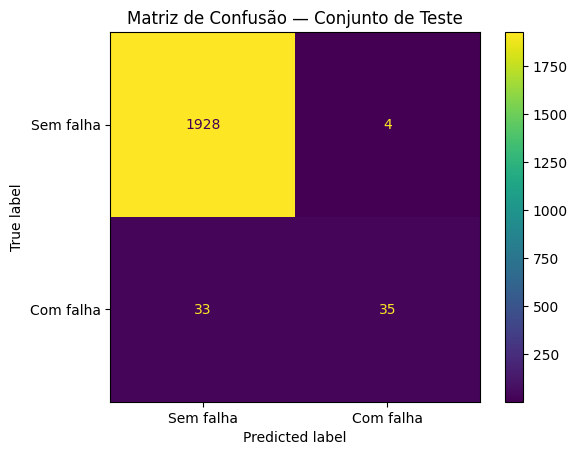

In [24]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Sem falha", "Com falha"]
)

plt.title("Matriz de Confusão — Conjunto de Teste")
plt.show()


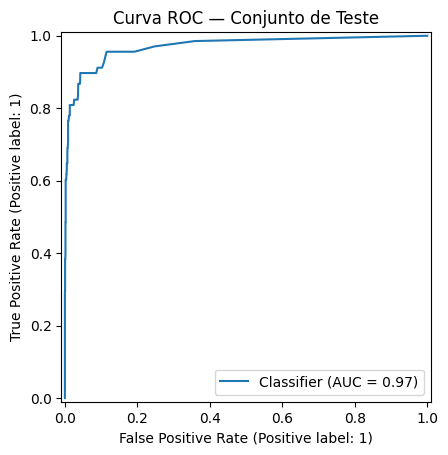

In [25]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("Curva ROC — Conjunto de Teste")
plt.show()


### Interpretação — Avaliação do modelo final

No conjunto de teste, o modelo Random Forest apresentou um desempenho altamente consistente, alcançando uma acurácia global de 98,15% e uma excelente área sob a curva ROC (AUC de 0,9709). A precisão foi de 89,74%, demonstrando que quase todas as falhas alertadas pelo modelo são reais, minimizando alarmes falsos. O recall de 51,47% indica que o modelo identificou pouco mais da metade das falhas reais presentes no conjunto de teste. Embora o resultado represente uma melhora significativa em relação à Regressão Logística, a quantidade de falsos negativos ainda constitui uma limitação importante para uma aplicação real de manutenção preditiva.


## 7. Exportação do modelo

O Pipeline completo será salvo com Joblib. Dessa forma, o mesmo arquivo conterá o pré-processamento e o classificador, permitindo que a futura interface Streamlit receba os dados brutos sem retreinar o modelo.


In [26]:
joblib.dump(
    best_model,
    "modelo_manutencao_preditiva.joblib"
)

print("Modelo salvo com sucesso!")


Modelo salvo com sucesso!


In [27]:
loaded_model = joblib.load(
    "modelo_manutencao_preditiva.joblib"
)

example = X_test.iloc[[0]]

print("Dados utilizados:")
display(example)

print("Predição:", loaded_model.predict(example)[0])
print(
    "Probabilidade de falha:",
    loaded_model.predict_proba(example)[0, 1]
)


Dados utilizados:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
2997,L,300.5,309.8,1345,62.7,153


Predição: 0
Probabilidade de falha: 0.10333333333333333


In [28]:
from google.colab import files

files.download("modelo_manutencao_preditiva.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Conclusão

Este projeto teve como objetivo desenvolver uma solução de Machine Learning para previsão de falhas em máquinas industriais utilizando o dataset AI4I 2020 Predictive Maintenance.

A análise exploratória permitiu compreender que as falhas estão fortemente correlacionadas com extremos operacionais de torque e velocidade de rotação.

Foi identificado um severo desbalanceamento de classes na variável alvo (apenas 3,39% de falhas), o que exigiu o uso de métricas alternativas à acurácia para uma avaliação realista.

Durante o pré-processamento, foram selecionadas características operacionais relevantes e descartados identificadores que não contribuiriam para a capacidade de generalização do modelo.

Foram avaliados os algoritmos Regressão Logística e Random Forest utilizando validação cruzada estratificada.

O modelo Random Forest apresentou o melhor equilíbrio entre as métricas avaliadas.

A métrica Recall teve importância especial neste problema devido ao alto custo financeiro e de segurança associado à não identificação de uma falha iminente na indústria.

No conjunto de teste, o modelo final obteve um excelente desempenho geral, com Acurácia de 98,15%, Precisão de 89,74%, Recall de 51,47% e uma excelente área sob a curva ROC (ROC-AUC de 97,09%).

Apesar dos resultados altamente satisfatórios, o modelo possui limitações, como a taxa de falsos negativos de quase 48% das falhas reais devido ao desbalanceamento crônico do dataset.

Como melhoria futura, poderiam ser avaliadas técnicas de sobreamostragem (como SMOTE), ajuste de hiperparâmetros por GridSearch e a utilização de algoritmos de boosting como XGBoost ou LightGBM.

Por fim, o modelo treinado foi integrado e exportado em formato Joblib, estando pronto para ser incorporado a uma interface interativa em Streamlit para simulações operacionais em tempo real.

## 9. Próxima etapa — Interface gráfica

Após validar o modelo, será criado um `app.py` em Streamlit com:

- campos para todas as features utilizadas pelo modelo;
- validação de entradas;
- botão para realizar a predição;
- classe prevista;
- probabilidade estimada de falha;
- mensagem amigável para entradas inválidas;
- carregamento do arquivo `.joblib` sem retreinamento.

Depois serão produzidos os prints da tela principal, de uma predição válida e de um caso de erro tratado para inclusão no relatório final em PDF.


In [32]:
import ipywidgets as widgets
from IPython.display import display, HTML

# Lista de itens obrigatórios do checklist (todos validados como True)
itens_checklist = [
    ("Cabeçalho e Contexto: título, nomes, dataset, objetivo e técnica escolhida.", True),
    ("Importação de Bibliotecas: importe tudo no início e defina np.random.seed(42).", True),
    ("Carregamento e Inspeção: tipos de dados, nulos, duplicatas e df.describe().", True),
    ("Análise Exploratória (EDA): mínimo de 4 gráficos com interpretação escrita.", True),
    ("Pré-processamento: tratamento de nulos, encoding, normalização e split treino/teste.", True),
    ("Modelagem: treine e compare pelo menos 2 modelos diferentes.", True),
    ("Avaliação do Modelo: métricas calculadas e comparadas (acurácia, precisão, recall, F1, AUC).", True),
    ("Exportação do Modelo: salve o modelo e transformadores usando joblib.", True),
    ("Conclusão: mínimo de 10 linhas justificando escolhas, melhor modelo, descobertas e limitações.", True)
]

print("=== Validação do Checklist da Estrutura Obrigatória ===\n")

checkboxes = []
for texto, status_sugerido in itens_checklist:
    chk = widgets.Checkbox(
        value=status_sugerido,
        description=texto,
        disabled=False,
        indent=False,
        layout=widgets.Layout(width='100%')
    )
    checkboxes.append(chk)
    display(chk)

output_validador = widgets.Output()
display(output_validador)

def validar_checklist(b):
    with output_validador:
        output_validador.clear_output()
        total = len(checkboxes)
        concluidos = sum([1 for c in checkboxes if c.value])
        percentual = (concluidos / total) * 100

        if percentual == 100:
            display(HTML("<div style='color: green; font-weight: bold; margin-top: 10px;'>✔️ Parabéns! Todos os requisitos foram cumpridos e validados!</div>"))
        else:
            display(HTML(f"<div style='color: orange; font-weight: bold; margin-top: 10px;'>⚠️ Atenção: {concluidos} de {total} itens concluídos ({percentual:.1f}%). Certifique-se de preencher as seções de texto pendentes na conclusão!</div>"))

botao_validar = widgets.Button(description="Validar Estrutura", button_style='primary')
botao_validar.on_click(validar_checklist)
display(botao_validar)
validar_checklist(None)

=== Validação do Checklist da Estrutura Obrigatória ===



Checkbox(value=True, description='Cabeçalho e Contexto: título, nomes, dataset, objetivo e técnica escolhida.'…

Checkbox(value=True, description='Importação de Bibliotecas: importe tudo no início e defina np.random.seed(42…

Checkbox(value=True, description='Carregamento e Inspeção: tipos de dados, nulos, duplicatas e df.describe().'…

Checkbox(value=True, description='Análise Exploratória (EDA): mínimo de 4 gráficos com interpretação escrita.'…

Checkbox(value=True, description='Pré-processamento: tratamento de nulos, encoding, normalização e split trein…

... (2 outputs left out)

Checkbox(value=True, description='Exportação do Modelo: salve o modelo e transformadores usando joblib.', inde…

Checkbox(value=True, description='Conclusão: mínimo de 10 linhas justificando escolhas, melhor modelo, descobe…

Output()

Button(button_style='primary', description='Validar Estrutura', style=ButtonStyle())